In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
face_cascade = cv2.CascadeClassifier("/content/drive/MyDrive/class/haarcascade_frontalface_default.xml")
#The .xml file contains trained Haar Cascade data for detecting faces, face_cascade becomes an object you can use to find faces in images
eye_cascade = cv2.CascadeClassifier('/content/drive/MyDrive/class/haarcascade_eye.xml')
#This .xml file is trained to detect eyes, eye_cascade is used to find eyes (usually inside detected faces)

In [ ]:
def adjusted_detect_face(img):
    face_img = img.copy()
    face_rect = face_cascade.detectMultiScale(face_img, scaleFactor=1.2, minNeighbors=5)

    for (x, y, w, h) in face_rect:
        cv2.rectangle(face_img, (x, y), (x + w, y + h), (255, 255, 255), 10)

    return face_img

face_cascade: Loaded from XML earlier, Knows how a face looks
detectMultiScale: This is the function that finds faces

In [ ]:
def detect_eyes(img):
    eye_img = img.copy()
    eye_rect = eye_cascade.detectMultiScale(eye_img, scaleFactor=1.2, minNeighbors=5)

    for (x, y, w, h) in eye_rect:
        cv2.rectangle(eye_img, (x, y), (x + w, y + h), (255, 255, 255), 10)

    return eye_img

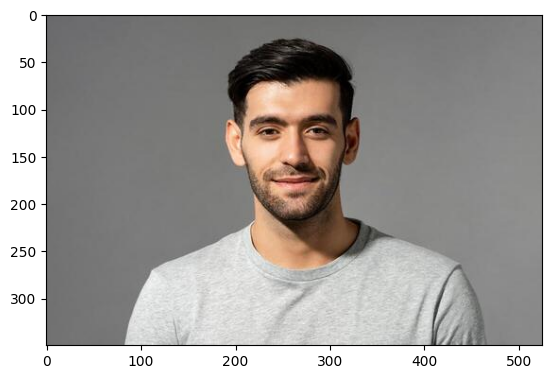

In [ ]:
img = cv2.imread('/content/drive/MyDrive/class/close-up-portrait-of-smiling-handsome-young-caucasian-man-face-looking-at-camera-on-isolated-light-gray-studio-background-photo.jpg')
img_copy1 = img.copy()
# Creates an independent copy of the image
# Any changes made to img_copy1 will NOT affect the original img
img_copy2 = img.copy()
img_copy3 = img.copy()

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
# OpenCV reads images in BGR format (Blue-Green-Red)
# Matplotlib expects RGB format (Red-Green-Blue)
# So cv2.cvtColor converts BGR → RGB for correct color display
# plt.imshow() then displays the image in a plot window

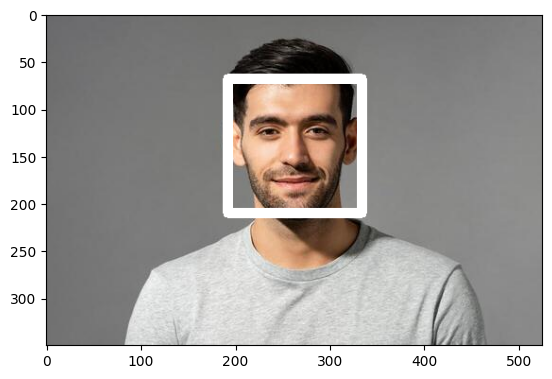

True

In [ ]:
face = adjusted_detect_face(img_copy1)
plt.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB))
plt.show()
cv2.imwrite('face.jpg', face)

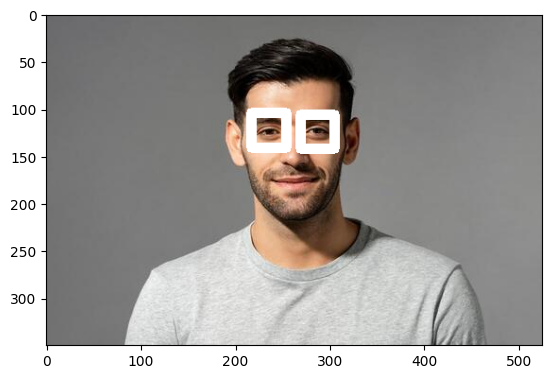

True

In [ ]:
eyes = detect_eyes(img_copy2)
plt.imshow(cv2.cvtColor(eyes, cv2.COLOR_BGR2RGB))
plt.show()
cv2.imwrite('eyes.jpg', eyes)

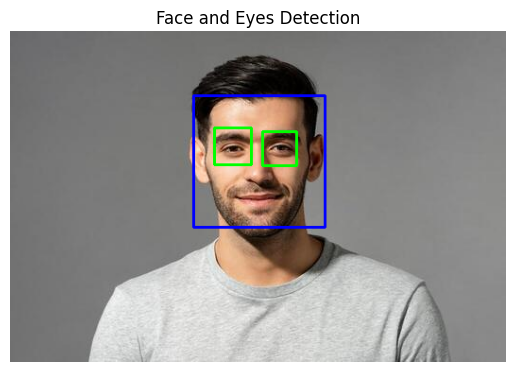

True

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load image
img = cv2.imread('/content/drive/MyDrive/class/close-up-portrait-of-smiling-handsome-young-caucasian-man-face-looking-at-camera-on-isolated-light-gray-studio-background-photo.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Load Haar cascades
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

eye_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_eye.xml')

# Detect faces
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.3, minNeighbors=5)

# Loop over faces
for (x, y, w, h) in faces:
    # Draw rectangle around face
    cv2.rectangle(img, (x, y), (x+w, y+h), (255, 0, 0), 2)

    # Region of interest (face area)
    roi_gray = gray[y:y+h, x:x+w]
    roi_color = img[y:y+h, x:x+w]

    # Detect eyes inside face
    eyes = eye_cascade.detectMultiScale(roi_gray)

    for (ex, ey, ew, eh) in eyes:
        cv2.rectangle(roi_color, (ex, ey), (ex+ew, ey+eh), (0, 255, 0), 2)

# Show result
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Face and Eyes Detection")
plt.axis('off')
plt.show()

# Save output
cv2.imwrite('face_eyes_detected.jpg', img)

In [ ]:
import cv2

In [ ]:
faceCascade = cv2.CascadeClassifier("/content/drive/MyDrive/class/haarcascade_frontalface_default.xml")

In [ ]:
im = cv2.imread("/content/drive/MyDrive/class/download (5).jpg")
gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

In [ ]:
faces = faceCascade.detectMultiScale(gray, scaleFactor=1.1,minNeighbors=5, minSize=(30, 30),flags=cv2.CASCADE_SCALE_IMAGE)

In [ ]:
print("faces detected: ",len(faces))

faces detected:  2


In [ ]:
for f in faces:
    [x,y,w,h]=f
    cv2.rectangle(im, (x, y), (x+w, y+h), (0, 255, 0), 2)

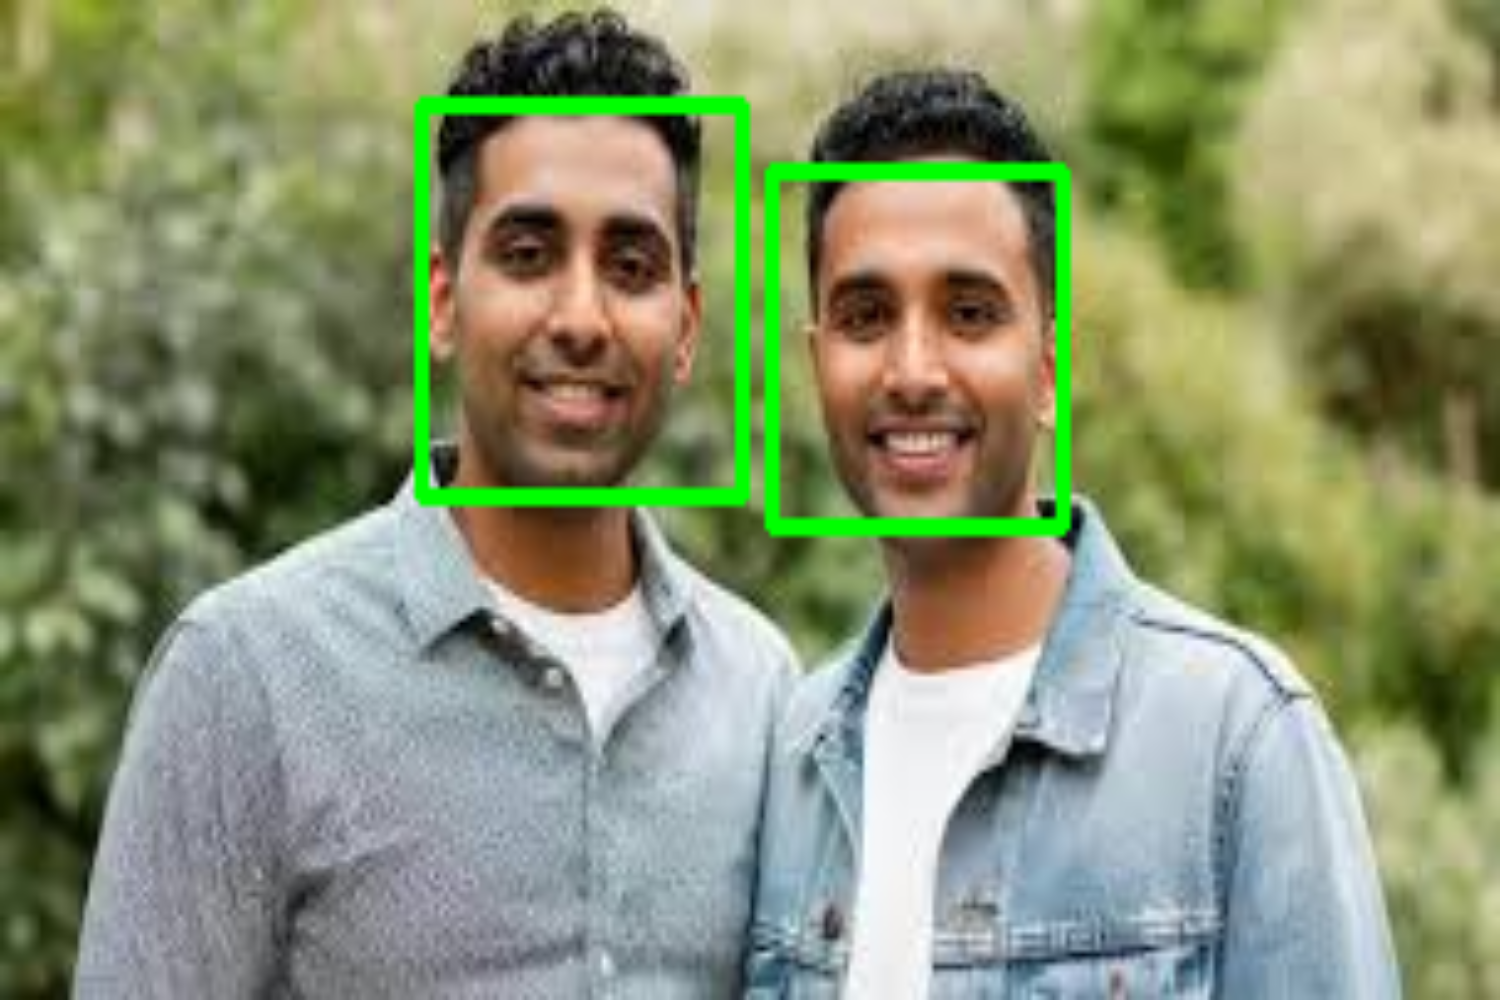

In [ ]:
from google.colab.patches import cv2_imshow
cv2_imshow(cv2.resize(im, (1500, 1000)))

In [ ]:
im = cv2.imread("/content/drive/MyDrive/class/TTHS1VR.jpg")
gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

In [ ]:
faces = faceCascade.detectMultiScale(gray, scaleFactor=1.1,minNeighbors=15, minSize=(30, 30),flags=cv2.CASCADE_SCALE_IMAGE)

In [ ]:
print("faces detected: ",len(faces))

faces detected:  4


In [ ]:
for f in faces:
    [x,y,w,h]=f
    cv2.rectangle(im, (x, y), (x+w, y+h), (0, 255, 0), 2)

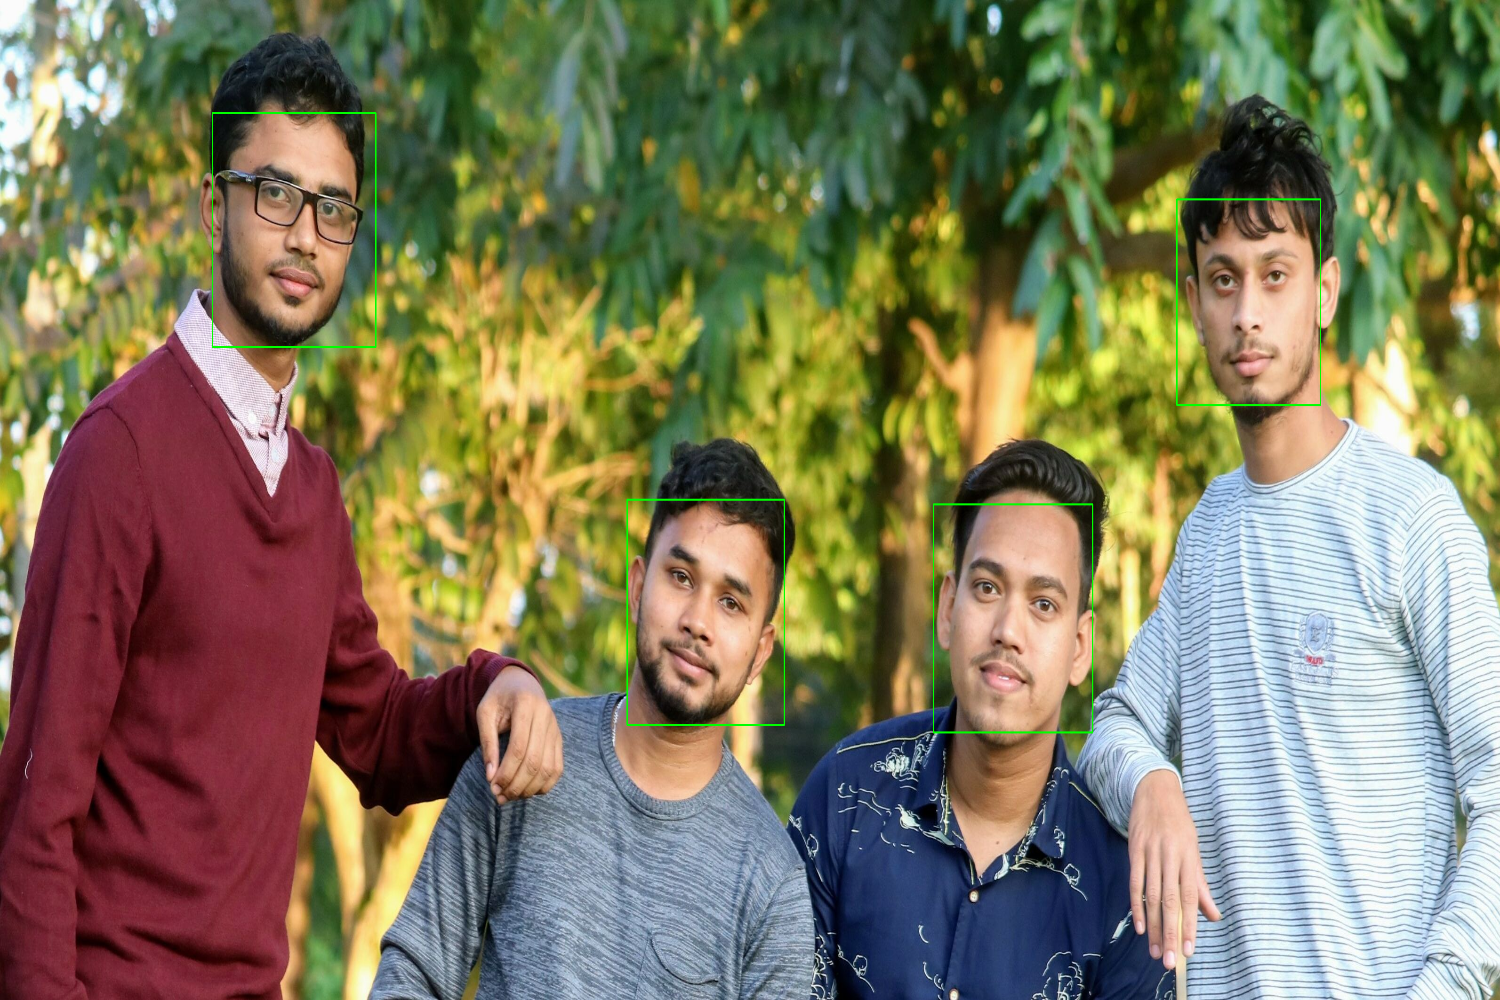

In [ ]:
from google.colab.patches import cv2_imshow
cv2_imshow(cv2.resize(im, (1500, 1000)))
# cv2.waitKey(0) is not needed with cv2_imshow as it displays statically

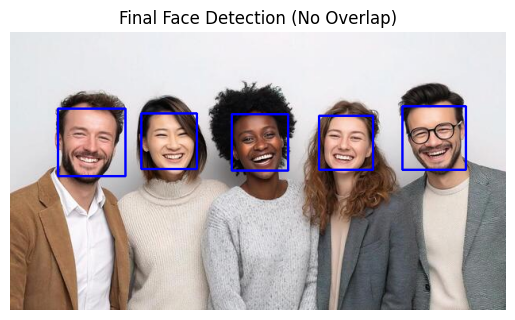

True

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------- Non-Max Suppression ----------
def non_max_suppression(boxes, overlapThresh=0.3):
    if len(boxes) == 0:
        return []

    boxes = np.array(boxes)

    x1 = boxes[:, 0]
    y1 = boxes[:, 1]
    x2 = boxes[:, 0] + boxes[:, 2]
    y2 = boxes[:, 1] + boxes[:, 3]

    area = (x2 - x1) * (y2 - y1)
    idxs = np.argsort(y2)

    pick = []

    while len(idxs) > 0:
        last = idxs[-1]
        pick.append(last)

        xx1 = np.maximum(x1[last], x1[idxs[:-1]])
        yy1 = np.maximum(y1[last], y1[idxs[:-1]])
        xx2 = np.minimum(x2[last], x2[idxs[:-1]])
        yy2 = np.minimum(y2[last], y2[idxs[:-1]])

        w = np.maximum(0, xx2 - xx1)
        h = np.maximum(0, yy2 - yy1)

        overlap = (w * h) / area[idxs[:-1]]

        idxs = idxs[np.where(overlap <= overlapThresh)[0]]

    return boxes[pick].astype("int")


# ---------- Load Image ----------
img = cv2.imread('/content/drive/MyDrive/class/five-people-smiling-and-standing-together-free-photo.jpeg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# ---------- Load Haar Cascade ----------
faceCascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# ---------- Detect Faces ----------
faces = faceCascade.detectMultiScale(
    gray,
    scaleFactor=1.03,
    minNeighbors=45,
    minSize=(30, 30)
)



# ---------- Apply Non-Max Suppression ----------
faces = non_max_suppression(faces)



# ---------- Draw Final Boxes ----------
for (x, y, w, h) in faces:
    cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 0), 2)

# ---------- Show Result ----------
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Final Face Detection (No Overlap)")
plt.axis('off')
plt.show()

# ---------- Save Output ----------
cv2.imwrite('final_faces.jpg', img)

HOG


Visualizing HOG Features with Python and skimage

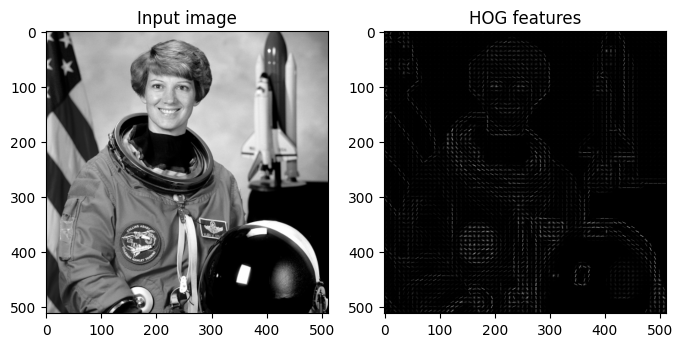

In [ ]:
from skimage import color
from skimage.feature import hog
from skimage import data, exposure, io
import matplotlib.pyplot as plt

# Loading an example image
image = data.astronaut()
image_gray = color.rgb2gray(image) # Converting image to grayscale

# Extract HOG features
features, hog_image = hog(image_gray, orientations=9, pixels_per_cell=(8, 8),
                          cells_per_block=(2, 2), visualize=True)
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Input image')

plt.subplot(1, 2, 2)
plt.imshow(hog_image, cmap='gray')
plt.title('HOG features')
plt.show()

Customizing HOG Feature Visualization with skimage

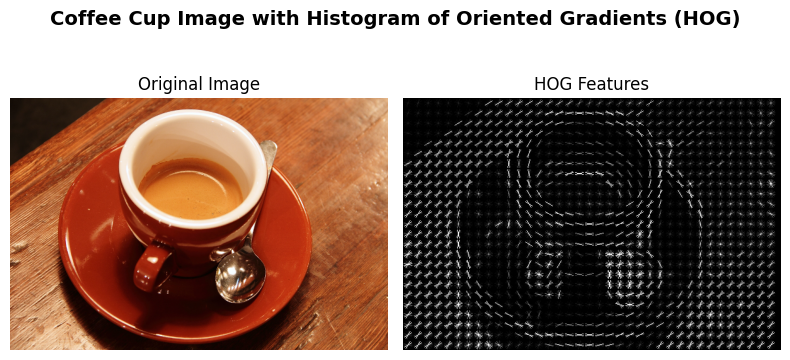

In [ ]:
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import data, exposure
image = data.coffee()

# Compute HOG features
fd, hog_image = hog(image, orientations=8, pixels_per_cell=(16, 16), cells_per_block=(1, 1), visualize=True, channel_axis=-1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8,4), sharex=True, sharey=True)
fig.suptitle('Coffee Cup Image with Histogram of Oriented Gradients (HOG)', fontsize=14, fontweight='bold')
ax1.imshow(image, cmap=plt.cm.gray)
ax1.set_title('Original Image')
ax1.axis('off')

# Rescale histogram for better display
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

# HOG Features
ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)
ax2.set_title('HOG Features')
ax2.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.85)  # Adjust the layout to accommodate the title
plt.show()

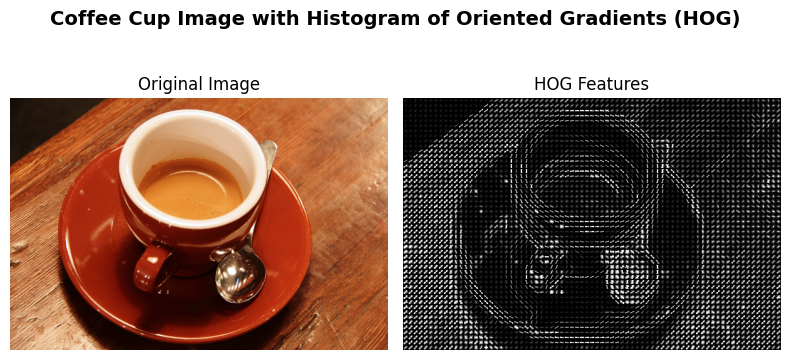

In [ ]:
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import data, exposure
image = data.coffee()

# Compute HOG features
fd, hog_image = hog(image, orientations=47, pixels_per_cell=(8, 8), cells_per_block=(1, 1), visualize=True, channel_axis=-1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8,4), sharex=True, sharey=True)
fig.suptitle('Coffee Cup Image with Histogram of Oriented Gradients (HOG)', fontsize=14, fontweight='bold')
ax1.imshow(image, cmap=plt.cm.gray)
ax1.set_title('Original Image')
ax1.axis('off')

# Rescale histogram for better display
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

# HOG Features
ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)
ax2.set_title('HOG Features')
ax2.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.85)  # Adjust the layout to accommodate the title
plt.show()

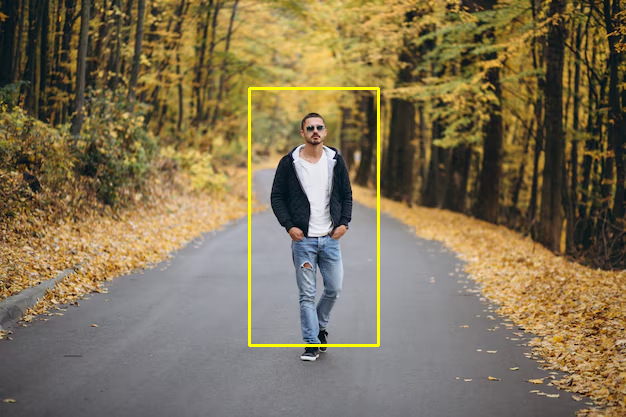

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Define check inside function
def is_inside(o,i):
    ox, oy, ow, oh = o
    ix, iy, iw, ih = i
    return ox > ix and oy > iy and ox + ow < ix + iw and oy + oh < iy + ih

# Define function to draw person
def draw_person(image, person):
    x, y, w, h = person
    cv2.rectangle(image, (x,y), (x+w, y+h), (0,255,255),2)

# Image import
# img = cv2.imread("/content/1000_F_184131402_MvaB84XRVQnewk7gQdWzkG2LRVPjSlDf.jpg")
img = cv2.imread("/content/drive/MyDrive/class/p2.avif")

# Define HOG and determine detecting method (we're using default)
hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

# Detect mullti scale
found, w = hog.detectMultiScale(img)
# Founded people array
found_filtered = []

# If detect people, append it to founded array
for ri, r in enumerate(found):
    for qi, q in enumerate(found):
        if ri != qi and is_inside(r,q):
            break
        else:
            found_filtered.append(r)

# Draw rectangles around the person
for person in found_filtered:
    draw_person(img, person)

# Show detected people
cv2_imshow(img)
# cv2.waitKey(0) and cv2.destroyAllWindows() are not needed with cv2_imshow